## Задание по библиотекам Pandas и Matplotlib
### Лабораторная работа № 4 (в методичке — № 3) по дисциплине "Технологии программирования"

Подключаем необходимые библиотеки:

**Вариант 1.** Задание 2 — п. 1 (количество женщин старше 50 лет на борту),
задание 4 — п. 1 (утверждение «чем дороже билет, тем выше вероятность выжить»).

**Технологии:** Python 3, Pandas, NumPy, Matplotlib, Jupyter Notebook / Google Colab.

In [1]:
import os
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline
pd.set_option('display.width', 140)
print('pandas', pd.__version__, '| numpy', np.__version__)

pandas 3.1.1 | numpy 2.5.5


Скачиваем датасет с информацией о пассажирах Титаника:

In [2]:
# В оригинале использовалась команда `!wget`; загрузка средствами Python работает
# одинаково в Google Colab, Jupyter и на Windows.
URL = 'https://web.stanford.edu/class/archive/cs/cs109/cs109.1166/stuff/titanic.csv'
if not os.path.exists('titanic.csv'):
    urllib.request.urlretrieve(URL, 'titanic.csv')

Проверяем наличие скачанного датасета:

In [3]:
print([f for f in os.listdir('.') if f.endswith('.csv')])

['titanic.csv']


Значения колонок датасета следующие (__в соответствии с информацией с сайта__):
*    Survived Indicator (выжил пассажир или нет)
*    Passenger Class (класс)
*    Name (имя)
*    Sex (пол)
*    Age (возраст)
*    Siblings/Spouses Aboard (есть ли братья, сестры или супруг(а) на борту)
*    Parents/Children Aboard (есть ли родители или дети на борту)
*    Fare paid in £s (цена билета в фунтах стерлингов)

Загружаем данные и формируем Pandas DataFrame:

In [4]:
df = pd.read_csv('titanic.csv')
df

,Survived,Pclass,Name,Sex,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare
0,0,3,Mr. Owen Harris Braund,male,22.0,1,0,7.2500
1,1,1,Mrs. John Bradley (Florence Briggs Thayer) Cum...,female,38.0,1,0,71.2833
2,1,3,Miss. Laina Heikkinen,female,26.0,0,0,7.9250
3,1,1,Mrs. Jacques Heath (Lily May Peel) Futrelle,female,35.0,1,0,53.1000
4,0,3,Mr. William Henry Allen,male,35.0,0,0,8.0500
...,...,...,...,...,...,...,...,...
882,0,2,Rev. Juozas Montvila,male,27.0,0,0,13.0000
883,1,1,Miss. Margaret Edith Graham,female,19.0,0,0,30.0000
884,0,3,Miss. Catherine Helen Johnston,female,7.0,1,2,23.4500
885,1,1,Mr. Karl Howell Behr,male,26.0,0,0,30.0000


__С использованием датафрейма нужно выполнить следующие задания__.

1. Определите, содержит ли какой-нибудь столбец датасета пропущенные значения.

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 887 entries, 0 to 886
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Survived                 887 non-null    int64  
 1   Pclass                   887 non-null    int64  
 2   Name                     887 non-null    str    
 3   Sex                      887 non-null    str    
 4   Age                      887 non-null    float64
 5   Siblings/Spouses Aboard  887 non-null    int64  
 6   Parents/Children Aboard  887 non-null    int64  
 7   Fare                     887 non-null    float64
dtypes: float64(2), int64(4), str(2)
memory usage: 55.6 KB


In [6]:
missing = df.isna().sum()
print(missing)
print('Есть пропуски хотя бы в одном столбце:', missing.any())

Survived                   0
Pclass                     0
Name                       0
Sex                        0
Age                        0
Siblings/Spouses Aboard    0
Parents/Children Aboard    0
Fare                       0
dtype: int64
Есть пропуски хотя бы в одном столбце: False


In [7]:
# Пропусков в виде NaN нет, но проверим «скрытые» пропуски — нулевую цену билета
print('Пассажиров с Fare = 0:', (df['Fare'] == 0).sum())
df[df['Fare'] == 0].head()

Пассажиров с Fare = 0: 15


,Survived,Pclass,Name,Sex,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare
178,0,3,Mr. Lionel Leonard,male,36.0,0,0,0.0
261,0,1,Mr. William Harrison,male,40.0,0,0,0.0
269,1,3,Mr. William Henry Tornquist,male,25.0,0,0,0.0
275,0,2,Mr. Francis Parkes,male,21.0,0,0,0.0
300,0,3,Mr. William Cahoone Jr Johnson,male,19.0,0,0,0.0


**Ответ.** Ни один столбец датасета не содержит пропущенных значений (`isna().sum()` равно 0 для всех 8 столбцов,
887 непустых значений в каждом). При этом у 15 пассажиров цена билета равна 0 — это, скорее всего, служебные
или неизвестные значения («скрытые» пропуски), которые стоит учитывать при анализе цен.

2. В соответствии с вариантом, определите:

   1. Количество женщин старше 50 лет на борту.
   2. Количество пассажиров, путешествующих вторым классом вместе с родителями или детьми.
   3. Число погибших детей в возрасте до 12 лет, путешествующих первым классом.
   4. Среднее значение коэффициента выживаемости десяти пассажиров третьего класса с самыми дорогими билетами.
   5. Среднее значение цены билета пассажиров, путешествующих без родственников.

In [8]:
# Вариант 1: количество женщин старше 50 лет на борту
women_over_50 = df[(df['Sex'] == 'female') & (df['Age'] > 50)]
print('Количество женщин старше 50 лет:', len(women_over_50))
women_over_50.sort_values('Age')

Количество женщин старше 50 лет: 18


,Survived,Pclass,Name,Sex,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare
761,1,1,Mrs. John C (Anna Andrews) Hogeboom,female,51.0,1,0,77.9583
588,1,1,Mrs. Walter Bertram (Martha Eustis) Stephenson,female,52.0,1,0,78.2667
816,1,1,Mrs. Charles Melville (Clara Jennings Gregg) Hays,female,52.0,1,1,93.5000
568,1,1,Mrs. Edward Dale (Charlotte Lamson) Appleton,female,53.0,2,0,51.4792
493,1,1,Miss. Elizabeth Mussey Eustis,female,54.0,1,0,78.2667
770,1,2,Mrs. Elizabeth (Eliza Needs) Hocking,female,54.0,1,3,23.0000
510,1,1,Mrs. Martin (Elizabeth L. Barrett) Rothschild,female,54.0,1,0,59.4000
15,1,2,Mrs. (Mary D Kingcome) Hewlett,female,55.0,0,0,16.0000
875,1,1,Mrs. Thomas Jr (Lily Alexenia Wilson) Potter,female,56.0,0,1,83.1583
768,0,2,Mrs. (Mary) Mack,female,57.0,0,0,10.5000


**Ответ.** На борту было **18 женщин старше 50 лет** (условие строгое: `Age > 50`).

3. Постройте диаграмму распределения значений цены билета по всем пассажирам. Проинтерпретируйте результат. Можно ли сказать, что в данных наблюдаются выбросы?

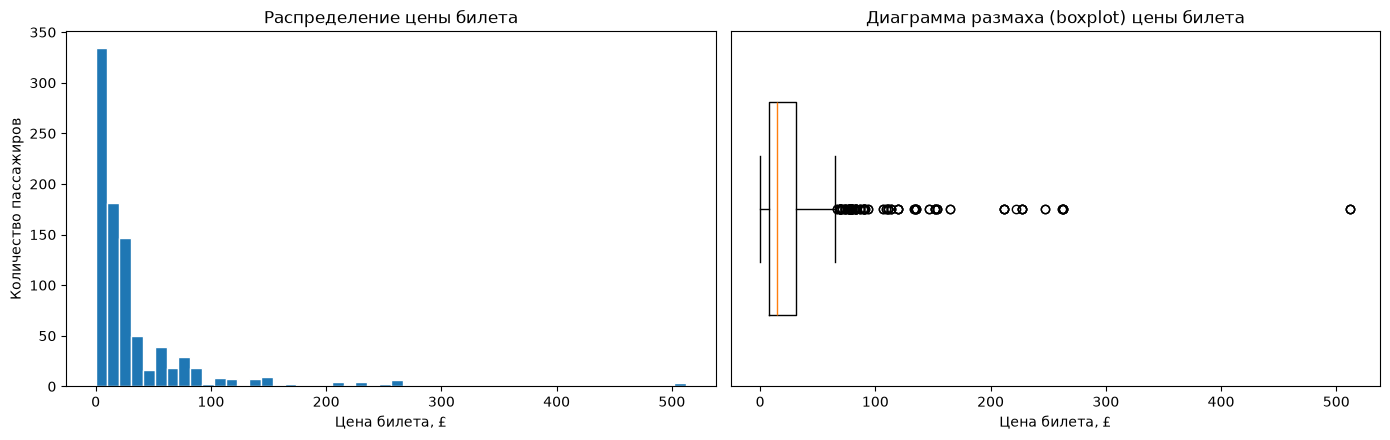

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].hist(df['Fare'], bins=50, color='tab:blue', edgecolor='white')
axes[0].set_title('Распределение цены билета')
axes[0].set_xlabel('Цена билета, £')
axes[0].set_ylabel('Количество пассажиров')

axes[1].boxplot(df['Fare'], orientation='horizontal', widths=0.6)
axes[1].set_title('Диаграмма размаха (boxplot) цены билета')
axes[1].set_xlabel('Цена билета, £')
axes[1].set_yticks([])

plt.tight_layout()
plt.show()

In [10]:
fare = df['Fare']
q1, q3 = fare.quantile([0.25, 0.75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr
print(fare.describe().round(2))
print(f'\nIQR = {iqr:.2f}, верхняя граница усов = Q3 + 1.5·IQR = {upper:.2f}')
print('Выбросов по правилу 1.5·IQR:', (fare > upper).sum())
print(f'Коэффициент асимметрии: {fare.skew():.2f}')
print('Самые дорогие билеты:', sorted(fare.nlargest(5).round(2)))

count    887.00
mean      32.31
std       49.78
min        0.00
25%        7.92
50%       14.45
75%       31.14
max      512.33
Name: Fare, dtype: float64

IQR = 23.21, верхняя граница усов = Q3 + 1.5·IQR = 65.96
Выбросов по правилу 1.5·IQR: 116
Коэффициент асимметрии: 4.78
Самые дорогие билеты: [263.0, 263.0, 512.33, 512.33, 512.33]


**Интерпретация.** Распределение цены билета сильно **скошено вправо** (асимметрия ≈ 4.8): у большинства
пассажиров дешевые билеты (медиана ≈ 14.5 £, 75 % билетов дешевле 31.1 £), а среднее (≈ 32.3 £) смещено
вверх небольшим числом очень дорогих билетов (до 512 £).

**Да, выбросы есть.** По правилу $Q_3 + 1.5\cdot IQR$ граница составляет ≈ 66 £, выше нее — 116 билетов;
особенно выделяются билеты за 512 £. Однако это не ошибки данных, а реальные дорогие каюты первого класса
(и групповые билеты на семью), поэтому удалять их без причины не следует — при моделировании лучше
использовать логарифм цены или устойчивые статистики (медиану).

4. В соответствии с вариантом, определите, верны ли следующие утверждения. Приведите доказательства ответа.

  1. Чем дороже билет, тем выше вероятность выжить.
  2. Мужчинам в катастрофе выжить проще.
  3. Чем больше родственников у человека, тем выше шанс того, что он купит билет третьего класса.
  4. Если Вам больше 70 лет, то шансов выжить в катастрофе у Вас практически нет.
  5. Чем больше родственников у чаловека, тем выше его шанс погибнуть.

**Вариант 1: «Чем дороже билет, тем выше вероятность выжить».**

Проверим утверждение несколькими способами: сравним цены у выживших и погибших, посчитаем долю выживших в
ценовых группах (квартилях), оценим корреляцию и проверим, не объясняется ли связь только классом каюты.

In [11]:
print('Цена билета у погибших (0) и выживших (1):')
print(df.groupby('Survived')['Fare'].agg(['mean', 'median']).round(2))

Цена билета у погибших (0) и выживших (1):
           mean  median
Survived               
0         22.21    10.5
1         48.40    26.0


              Доля выживших  Пассажиров
FareGroup                              
Q1 (дешевые)          0.218         238
Q2                    0.291         206
Q3                    0.457         221
Q4 (дорогие)          0.581         222


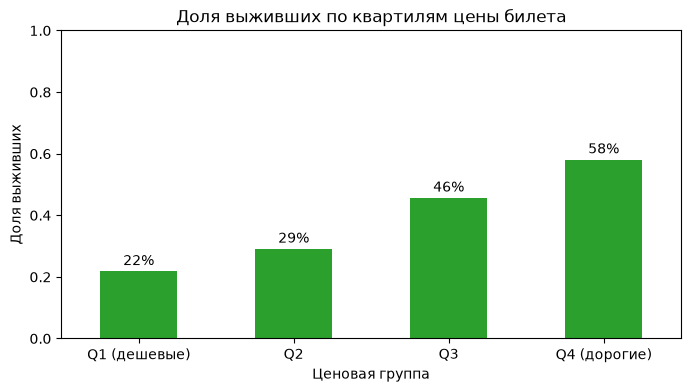

In [12]:
df_fare = df.assign(FareGroup=pd.qcut(df['Fare'], 4,
                                      labels=['Q1 (дешевые)', 'Q2', 'Q3', 'Q4 (дорогие)']))
by_group = df_fare.groupby('FareGroup', observed=True)['Survived'].agg(['mean', 'count'])
by_group.columns = ['Доля выживших', 'Пассажиров']
print(by_group.round(3))

ax = by_group['Доля выживших'].plot.bar(color='tab:green', rot=0, figsize=(8, 4))
ax.set_title('Доля выживших по квартилям цены билета')
ax.set_xlabel('Ценовая группа')
ax.set_ylabel('Доля выживших')
ax.set_ylim(0, 1)
for i, v in enumerate(by_group['Доля выживших']):
    ax.text(i, v + 0.02, f'{v:.0%}', ha='center')
plt.show()

In [13]:
print('Корреляция Спирмена (Fare, Survived): '
      f"{df['Fare'].corr(df['Survived'], method='spearman'):.3f}")
print('Корреляция Пирсона  (Fare, Survived): '
      f"{df['Fare'].corr(df['Survived']):.3f}")

# Не объясняется ли всё классом каюты? Смотрим зависимость внутри каждого класса.
print('\nКорреляция Спирмена внутри классов:')
print(df.groupby('Pclass')[['Fare', 'Survived']]
        .apply(lambda g: g['Fare'].corr(g['Survived'], method='spearman')).round(3))

inside = (df_fare.groupby(['Pclass', 'FareGroup'], observed=True)['Survived']
          .mean().unstack().round(2))
print('\nДоля выживших: класс × ценовая группа')
print(inside)

Корреляция Спирмена (Fare, Survived): 0.322
Корреляция Пирсона  (Fare, Survived): 0.256

Корреляция Спирмена внутри классов:
Pclass
1    0.271
2    0.214
3    0.057
dtype: float64

Доля выживших: класс × ценовая группа
FareGroup  Q1 (дешевые)    Q2    Q3  Q4 (дорогие)
Pclass                                           
1                  0.00   NaN  0.53          0.69
2                  0.00  0.38  0.60          0.55
3                  0.23  0.22  0.32          0.20


**Ответ: утверждение в целом верно.**

* Медианная цена билета у выживших (26 £) в 2.5 раза выше, чем у погибших (10.5 £).
* Доля выживших монотонно растет с ценой: ≈ 22 % в самой дешевой квартили → 29 % → 46 % → **58 %** в самой дорогой.
* Корреляция между ценой и выживанием положительная (Спирмен ≈ 0.32, Пирсон ≈ 0.26) — связь умеренная.

**Оговорки.** Связь во многом объясняется классом каюты: дорогие билеты — это первый класс, каюты которого
располагались выше и ближе к шлюпкам. Внутри 1-го и 2-го классов положительная связь сохраняется
(корреляция ≈ 0.27 и 0.21), а в 3-м классе почти исчезает (≈ 0.06): самые «дорогие» билеты третьего класса — это
групповые билеты больших семей, у которых шансы выжить были низкими. Кроме того, корреляция не означает
причинно-следственную связь: на выживание сильнее всего влияли пол и класс.

5. Столбец с именем пассажиров вряд ли будет иметь значение для последующего анализа данных. Удалите этот столбец из датафрейма. Выведите на экран полученный датасет.

In [14]:
df = df.drop(columns=['Name'])
df

,Survived,Pclass,Sex,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare
0,0,3,male,22.0,1,0,7.2500
1,1,1,female,38.0,1,0,71.2833
2,1,3,female,26.0,0,0,7.9250
3,1,1,female,35.0,1,0,53.1000
4,0,3,male,35.0,0,0,8.0500
...,...,...,...,...,...,...,...
882,0,2,male,27.0,0,0,13.0000
883,1,1,female,19.0,0,0,30.0000
884,0,3,female,7.0,1,2,23.4500
885,1,1,male,26.0,0,0,30.0000


6. Столбец "пол пассажира" является категориальным. Закодируйте его с помощью ohe-hot-кодирования (OHE). Выведите на экран полученный датасет.

In [15]:
df = pd.get_dummies(df, columns=['Sex'], prefix='Sex', dtype=int)
df

,Survived,Pclass,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare,Sex_female,Sex_male
0,0,3,22.0,1,0,7.2500,0,1
1,1,1,38.0,1,0,71.2833,1,0
2,1,3,26.0,0,0,7.9250,1,0
3,1,1,35.0,1,0,53.1000,1,0
4,0,3,35.0,0,0,8.0500,0,1
...,...,...,...,...,...,...,...,...
882,0,2,27.0,0,0,13.0000,0,1
883,1,1,19.0,0,0,30.0000,1,0
884,0,3,7.0,1,2,23.4500,1,0
885,1,1,26.0,0,0,30.0000,0,1


Столбец `Sex` заменен двумя бинарными столбцами `Sex_female` и `Sex_male` (в каждой строке ровно одна единица).
Для линейных моделей один из них можно удалить (`drop_first=True`), чтобы избежать мультиколлинеарности.

7. Постройте диаграмму рассеяния между признаками "Возраст" и "Цена билета". Проинтерпретируйте ответ.

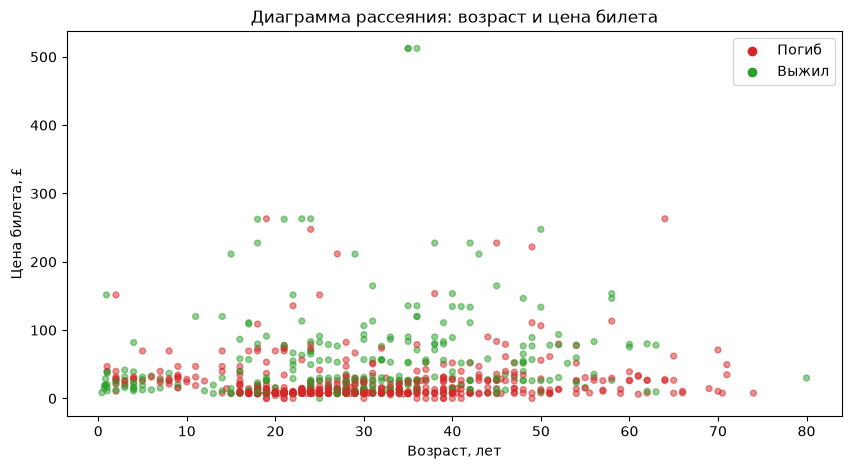

Корреляция Пирсона (Age, Fare): 0.112
Корреляция Спирмена (Age, Fare): 0.156


In [16]:
fig, ax = plt.subplots(figsize=(10, 5))
colors = df['Survived'].map({0: 'tab:red', 1: 'tab:green'})
ax.scatter(df['Age'], df['Fare'], c=colors, alpha=0.5, s=18)
ax.set_title('Диаграмма рассеяния: возраст и цена билета')
ax.set_xlabel('Возраст, лет')
ax.set_ylabel('Цена билета, £')
ax.scatter([], [], c='tab:red', label='Погиб')
ax.scatter([], [], c='tab:green', label='Выжил')
ax.legend()
plt.show()

print(f"Корреляция Пирсона (Age, Fare): {df['Age'].corr(df['Fare']):.3f}")
print(f"Корреляция Спирмена (Age, Fare): {df['Age'].corr(df['Fare'], method='spearman'):.3f}")

**Интерпретация.** Точки образуют горизонтальную «полосу» в области дешевых билетов (до ≈ 50 £) для всех возрастов;
выраженной зависимости между возрастом и ценой билета **нет** — коэффициент корреляции близок к нулю (≈ 0.11).
Дорогие билеты (> 100 £, 53 пассажира) встречаются у пассажиров от 1 года до 64 лет, половина из них — в возрасте
22–42 лет; на графике видны выбросы по цене (512 £). Среди пассажиров с дорогими билетами заметно больше выживших
(зеленые точки: 74 % против 39 % в среднем по датасету), что согласуется с выводом задания 4.

8. Отнормируйте значения признаков "Возраст" и "Цена билета". Выведите на экран полученный датасет.

In [17]:
# Min-max нормализация: x' = (x - min) / (max - min), значения приводятся к отрезку [0, 1]
cols = ['Age', 'Fare']
df_norm = df.copy()
df_norm[cols] = (df[cols] - df[cols].min()) / (df[cols].max() - df[cols].min())
print(df_norm[cols].describe().loc[['min', 'max', 'mean']].round(3))
df_norm

        Age   Fare
min   0.000  0.000
max   1.000  1.000
mean  0.365  0.063


,Survived,Pclass,Age,Siblings/Spouses Aboard,Parents/Children Aboard,Fare,Sex_female,Sex_male
0,0,3,0.271174,1,0,0.014151,0,1
1,1,1,0.472229,1,0,0.139136,1,0
2,1,3,0.321438,0,0,0.015469,1,0
3,1,1,0.434531,1,0,0.103644,1,0
4,0,3,0.434531,0,0,0.015713,0,1
...,...,...,...,...,...,...,...,...
882,0,2,0.334004,0,0,0.025374,0,1
883,1,1,0.233476,0,0,0.058556,1,0
884,0,3,0.082684,1,2,0.045771,1,0
885,1,1,0.321438,0,0,0.058556,0,1


Признаки `Age` и `Fare` приведены к диапазону [0, 1] (min-max нормализация). Альтернатива — стандартизация
$z = (x - \mu)/\sigma$; для `Fare` с сильными выбросами min-max сжимает большинство значений к нулю
(среднее ≈ 0.06), поэтому для этого признака часто сначала берут логарифм.

9. Постройте гистограммы распределения пассажиров по полу и по возрасту для каждого класса. Расположите гистограммы одна под другой. Оси абсцисс должны быть однаковыми.

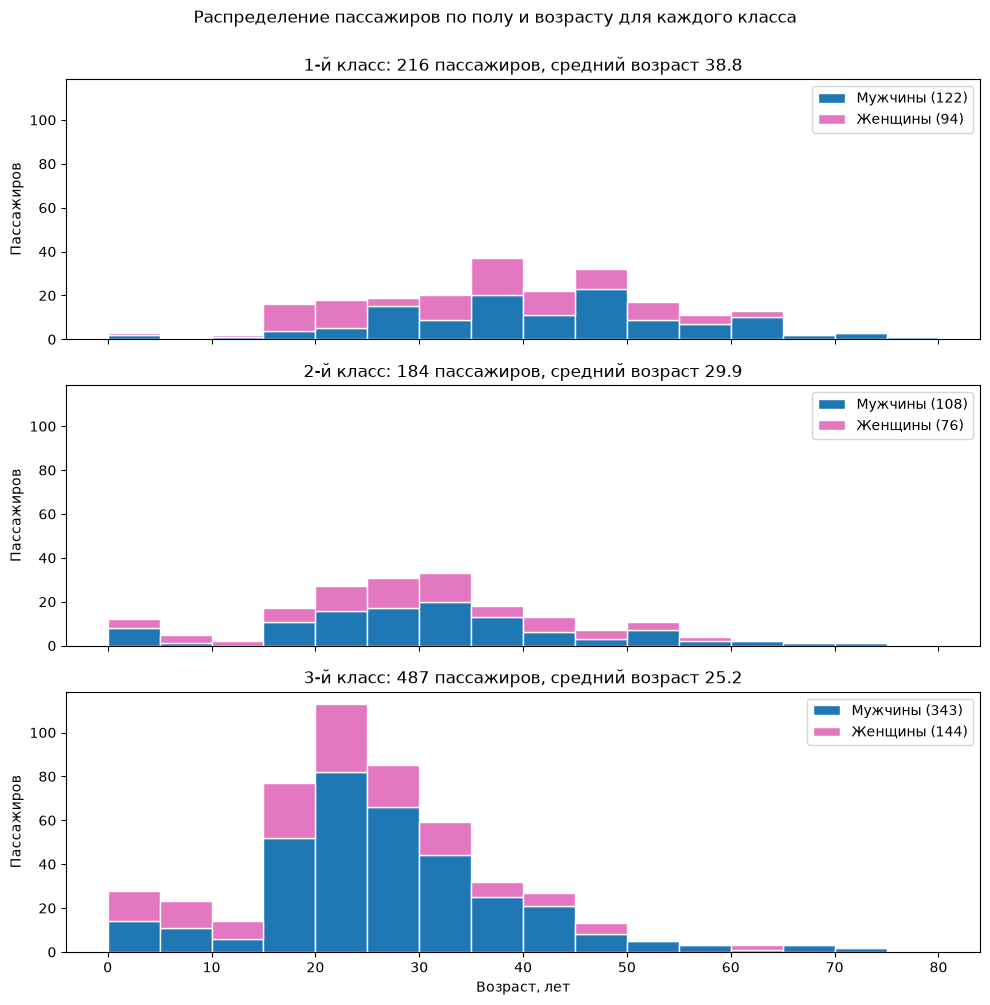

In [18]:
classes = sorted(df['Pclass'].unique())
bins = np.arange(0, 85, 5)

fig, axes = plt.subplots(len(classes), 1, figsize=(10, 10), sharex=True, sharey=True)
for ax, cls in zip(axes, classes):
    part = df[df['Pclass'] == cls]
    male = part.loc[part['Sex_male'] == 1, 'Age']
    female = part.loc[part['Sex_female'] == 1, 'Age']
    ax.hist([male, female], bins=bins, stacked=True,
            color=['tab:blue', 'tab:pink'], edgecolor='white',
            label=[f'Мужчины ({len(male)})', f'Женщины ({len(female)})'])
    ax.set_title(f'{cls}-й класс: {len(part)} пассажиров, средний возраст {part["Age"].mean():.1f}')
    ax.set_ylabel('Пассажиров')
    ax.legend(loc='upper right')
axes[-1].set_xlabel('Возраст, лет')
fig.suptitle('Распределение пассажиров по полу и возрасту для каждого класса', y=1.0)
plt.tight_layout()
plt.show()

In [19]:
print('Пассажиры по классу и полу:')
print(pd.crosstab(df['Pclass'], df['Sex_male'].map({1: 'мужчины', 0: 'женщины'}), margins=True))

Пассажиры по классу и полу:
Sex_male  женщины  мужчины  All
Pclass                         
1              94      122  216
2              76      108  184
3             144      343  487
All           314      573  887


**Интерпретация.** Гистограммы расположены одна под другой с общей осью абсцисс (возраст) — это позволяет
напрямую сравнивать классы. Третий класс самый многочисленный (487 человек), «молодой» (средний возраст ≈ 25 лет)
и преимущественно мужской (343 мужчины против 144 женщин). В первом классе пассажиры заметно старше
(средний возраст ≈ 39 лет), доля женщин выше. Второй класс занимает промежуточное положение.

10. Сделайте выводы по работе.

## Выводы

1. Датасет «Титаник» (887 пассажиров, 8 признаков) не содержит пропусков в виде NaN, однако 15 нулевых цен
   билета являются «скрытыми» пропусками.
2. **Вариант 1, задание 2:** на борту было 18 женщин старше 50 лет.
3. Распределение цены билета сильно скошено вправо, по правилу 1.5·IQR выявлено 116 выбросов — это реальные
   дорогие билеты первого класса, а не ошибки.
4. **Вариант 1, задание 4:** утверждение «чем дороже билет, тем выше вероятность выжить» в целом подтверждается:
   доля выживших растет от 22 % в самой дешевой квартили цены до 58 % в самой дорогой, корреляция положительная
   (Спирмен ≈ 0.32). Связь в основном опосредована классом каюты и в третьем классе практически отсутствует.
5. Выполнены типовые операции подготовки данных: удаление неинформативного столбца (`drop`), one-hot кодирование
   категориального признака (`get_dummies`), min-max нормализация числовых признаков.
6. Pandas позволяет компактно фильтровать, группировать и агрегировать данные (`groupby`, `qcut`, `crosstab`),
   а Matplotlib — наглядно визуализировать распределения (гистограммы, boxplot) и зависимости (диаграммы рассеяния).